In [8]:
import numpy as np
import pandas as pd

In [13]:
df = pd.read_csv(r'C:\Users\hp\glowup-campaign-analysis\data\glowup_campaigns.csv')

In [14]:
df

,CampaignID,CampaignName,StartDate,EndDate,Channel,Spend,LeadsGenerated,Conversions,RevenueGenerated,Clicks,Impressions
0,CMP1001,Email_Spring Renewal_1,2026-02-26,2026-03-15,Email,3228.92,273,43,2866.14,1182.0,31284.0
1,CMP1002,Event_Winter Matte_2,2025-10-28,2025-11-24,Event,34247.75,1540,450,39272.85,NaN,NaN
2,CMP1003,Social Media_Summer Glow_3,2026-04-10,2026-05-08,Social Media,3105.99,1615,136,8750.77,10099.0,492752.0
3,CMP1004,Email_Brand Awareness_4,2025-11-22,2025-12-17,Email,1838.62,265,63,3103.58,1267.0,21267.0
4,CMP1005,Email_Fall Hydration_5,2025-08-28,2025-09-17,Email,3329.39,235,43,2669.51,955.0,31016.0
5,CMP1006,Event_Flash Sale_6,2026-02-19,2026-03-12,Event,14334.12,454,130,14327.88,NaN,NaN
6,CMP1007,Influencer_Brand Awareness_7,2025-07-24,2025-08-09,Influencer,16354.01,1561,333,30409.21,3519.0,89692.0
7,CMP1008,Influencer_Brand Awareness_8,2026-01-01,2026-01-15,Influencer,21890.68,1038,161,11243.07,2272.0,104300.0
8,CMP1009,Event_Flash Sale_9,2025-07-11,2025-08-01,Event,14131.67,289,96,9196.35,NaN,NaN
9,CMP1010,Event_Winter Matte_10,2025-08-20,2025-09-03,Event,28225.18,1217,322,30377.04,NaN,NaN


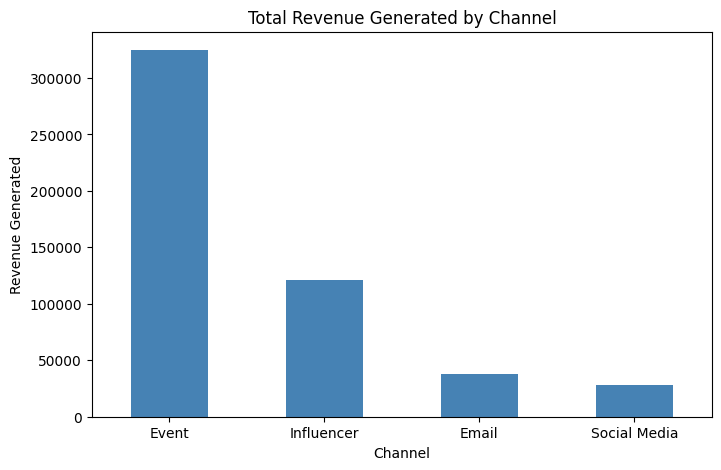

Channel
Event           324789.98
Influencer      121500.63
Email            37742.31
Social Media     27820.81
Name: RevenueGenerated, dtype: float64


In [19]:
import matplotlib.pyplot as plt

channel_revenue = df.groupby("Channel")["RevenueGenerated"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
channel_revenue.plot(kind="bar", color="steelblue")
plt.title("Total Revenue Generated by Channel")
plt.xlabel("Channel")
plt.ylabel("Revenue Generated")
plt.xticks(rotation=0)
plt.savefig("../images/revenue_by_channel.png", dpi=150, bbox_inches="tight")
plt.show()

print(channel_revenue)

   ![ROI by Channel](images/roi_by_channel.png)

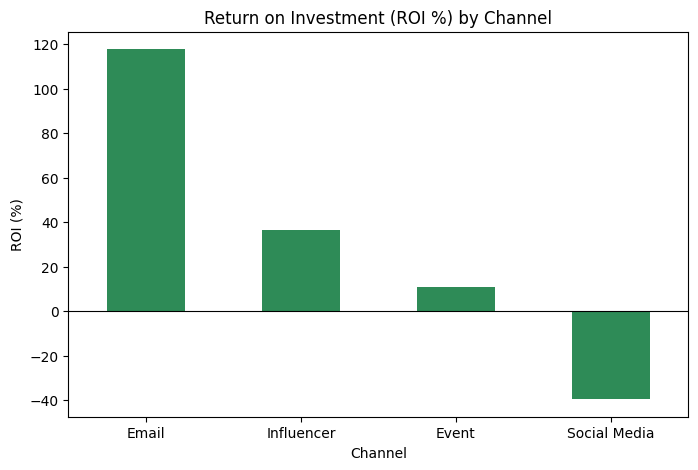

                  Spend  RevenueGenerated   ROI_%
Channel                                          
Email          17332.75          37742.31  117.75
Influencer     88922.22         121500.63   36.64
Event         293360.51         324789.98   10.71
Social Media   46048.81          27820.81  -39.58


In [20]:
channel_summary = df.groupby("Channel")[["Spend", "RevenueGenerated"]].sum()
channel_summary["ROI_%"] = (channel_summary["RevenueGenerated"] - channel_summary["Spend"]) / channel_summary["Spend"] * 100
channel_summary = channel_summary.sort_values("ROI_%", ascending=False)

plt.figure(figsize=(8, 5))
channel_summary["ROI_%"].plot(kind="bar", color="seagreen")
plt.title("Return on Investment (ROI %) by Channel")
plt.xlabel("Channel")
plt.ylabel("ROI (%)")
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=0)
plt.savefig("../images/roi_by_channel.png", dpi=150, bbox_inches="tight")
plt.show()

print(channel_summary.round(2))

   ![Conversion Rate by Channel](images/conversion_rate_by_channel.png)

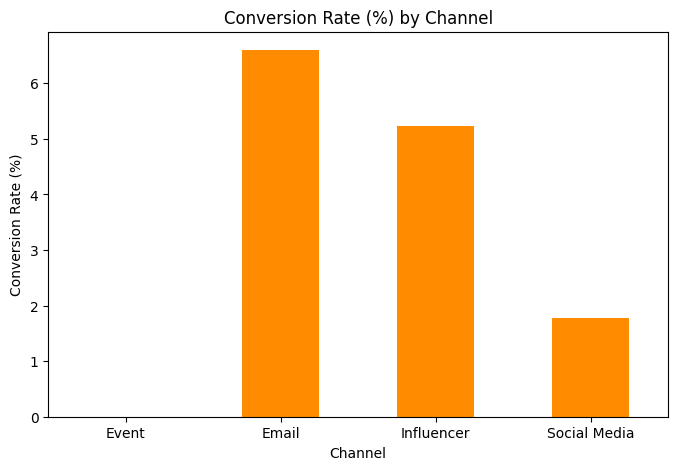

              Impressions   Clicks  Conversions  CTR_%  Conversion_Rate_%
Channel                                                                  
Event                 0.0      0.0         3294    NaN                inf
Email            262826.0  10580.0          698   4.03               6.60
Influencer       898090.0  27553.0         1440   3.07               5.23
Social Media    1635836.0  26483.0          471   1.62               1.78


In [22]:
funnel = df.groupby("Channel")[["Impressions", "Clicks", "Conversions"]].sum()
funnel["CTR_%"] = funnel["Clicks"] / funnel["Impressions"] * 100
funnel["Conversion_Rate_%"] = funnel["Conversions"] / funnel["Clicks"] * 100
funnel = funnel.sort_values("Conversion_Rate_%", ascending=False)

plt.figure(figsize=(8, 5))
funnel["Conversion_Rate_%"].plot(kind="bar", color="darkorange")
plt.title("Conversion Rate (%) by Channel")
plt.xlabel("Channel")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.savefig("../images/conversion_rate_by_channel.png", dpi=150, bbox_inches="tight")
plt.show()

print(funnel.round(2))

In [23]:
print(df.shape)
print(channel_summary.round(2))
print(funnel.round(2))

(30, 11)
                  Spend  RevenueGenerated   ROI_%
Channel                                          
Email          17332.75          37742.31  117.75
Influencer     88922.22         121500.63   36.64
Event         293360.51         324789.98   10.71
Social Media   46048.81          27820.81  -39.58
              Impressions   Clicks  Conversions  CTR_%  Conversion_Rate_%
Channel                                                                  
Event                 0.0      0.0         3294    NaN                inf
Email            262826.0  10580.0          698   4.03               6.60
Influencer       898090.0  27553.0         1440   3.07               5.23
Social Media    1635836.0  26483.0          471   1.62               1.78


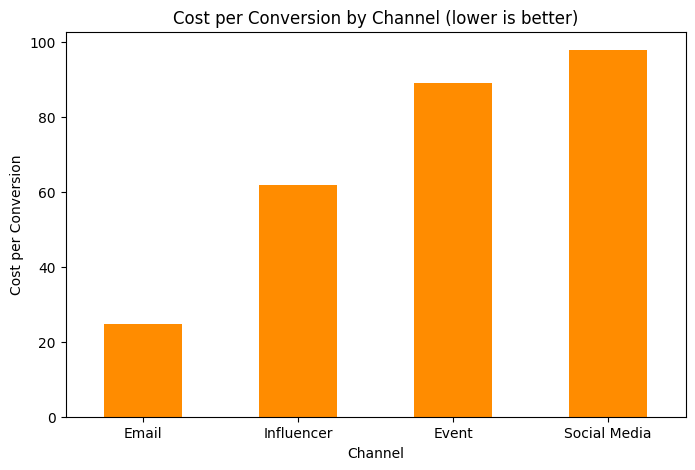

                  Spend  Conversions  Cost_per_Conversion
Channel                                                  
Email          17332.75          698                24.83
Influencer     88922.22         1440                61.75
Event         293360.51         3294                89.06
Social Media   46048.81          471                97.77


In [ ]:
cost = df.groupby("Channel")[["Spend", "Conversions"]].sum()
cost["Cost_per_Conversion"] = cost["Spend"] / cost["Conversions"]
cost = cost.sort_values("Cost_per_Conversion")

plt.figure(figsize=(8, 5))
cost["Cost_per_Conversion"].plot(kind="bar", color="darkorange")
plt.title("Cost per Conversion by Channel (lower is better)")
plt.xlabel("Channel")
plt.ylabel("Cost per Conversion")
plt.xticks(rotation=0)
plt.savefig("../images/cost_per_conversion_by_channel.png", dpi=150, bbox_inches="tight")
plt.show()

print(cost.round(2))# GlowUp Campaign Performance Analysis

Exploratory data analysis of GlowUp's marketing campaigns to find which channels deliver the best return on marketing spend.

## 📌 Project Objective
GlowUp runs marketing campaigns across four channels: Email, Influencer, Event and Social Media.
This project analyzes campaign spend, revenue, and conversions to answer one question:
**Which channels give the best return for every rupee spent, and where should the marketing budget go next?**

## 📂 Dataset
- **File:** `data/glowup_campaigns.csv`
- **Size:** 30 campaigns × 11 columns
- **Columns:** `CampaignID`, `CampaignName`, `StartDate`, `EndDate`, `Channel`, `Spend`, `LeadsGenerated`, `Conversions`, `RevenueGenerated`, `Clicks`, `Impressions`
- **Note:** Event campaigns have no impression or click data recorded (offline channel), so click-based metrics were calculated only for online channels.

## 🗂️ Project Structure
```
glowup-campaign-analysis/
├── data/
│   └── glowup_campaigns.csv              # Raw campaign dataset
├── notebooks/
│   └── GlowUp_EDA.ipynb                  # EDA, KPI calculation and charts
├── src/                                  # Reusable Python scripts
├── images/                               # Charts used in this README
│   ├── revenue_by_channel.png
│   ├── roi_by_channel.png
│   └── cost_per_conversion_by_channel.png
├── requirements.txt                      # Python dependencies
├── .gitignore
└── README.md
```

## ▶️ How to Run
1. Clone the repository:
   ```bash
   git clone https://github.com/Bhagyashree998/glowup-campaign-analysis.git
   cd glowup-campaign-analysis
   ```
2. Install dependencies:
   ```bash
   pip install -r requirements.txt
   ```
3. Open the notebook:
   ```bash
   jupyter notebook notebooks/GlowUp_EDA.ipynb
   ```
4. Run all cells (Kernel → Restart & Run All). Charts are saved to the `images/` folder.

## 📊 Key Analysis & Insights

### 1. Total Revenue by Channel
![Revenue by Channel](images/revenue_by_channel.png)

**Insight:** Events generated the most revenue (₹3.25 lakh, about 63% of the total), but they also consumed about 66% of the total budget. High revenue here comes mainly from high spending, not from efficiency.

### 2. ROI by Channel
![ROI by Channel](images/roi_by_channel.png)

**Insight:** Email delivered the highest ROI at **117.8%**, more than double what it cost, while using only about 4% of the budget. Influencer campaigns returned 36.6% and Events only 10.7%. **Social Media lost money (−39.6% ROI)**, earning back less than it cost.

### 3. Cost per Conversion by Channel
![Cost per Conversion by Channel](images/cost_per_conversion_by_channel.png)

**Insight:** Each Email conversion cost about **₹24.8**, roughly 4× cheaper than Social Media (**₹97.8**). Social Media had the most impressions (16.4 lakh) but the lowest conversion rate from clicks (1.8% vs 6.6% for Email), so its reach isn't turning into customers.

## 💻 Key Code Snippets

**ROI by channel**
```python
channel_summary = df.groupby("Channel")[["Spend", "RevenueGenerated"]].sum()
channel_summary["ROI_%"] = (
    (channel_summary["RevenueGenerated"] - channel_summary["Spend"])
    / channel_summary["Spend"] * 100
)
```

**Funnel metrics (CTR and conversion rate)**
```python
funnel = df.groupby("Channel")[["Impressions", "Clicks", "Conversions"]].sum()
funnel["CTR_%"] = funnel["Clicks"] / funnel["Impressions"] * 100
funnel["Conversion_Rate_%"] = funnel["Conversions"] / funnel["Clicks"] * 100
```

**Cost per conversion**
```python
cost = df.groupby("Channel")[["Spend", "Conversions"]].sum()
cost["Cost_per_Conversion"] = cost["Spend"] / cost["Conversions"]
```

## ✅ Conclusion
Across 30 campaigns, GlowUp spent ₹4.46 lakh and generated ₹5.12 lakh in revenue, an overall ROI of about 14.9%.
Email is the most efficient channel by far, with the highest ROI and the lowest cost per conversion, yet it receives the smallest share of the budget.
Events bring in the most revenue but at a low return, and Social Media is currently losing money.
**Recommendation:** increase investment in Email and Influencer campaigns, review the cost structure of Events, and pause or redesign Social Media campaigns until they become profitable.

## 🚀 Future Scope
- Track impressions and clicks for Event campaigns to compare them fairly with online channels
- Analyze performance over time using `StartDate` and `EndDate` to find the best campaign months and durations
- Use `LeadsGenerated` to study the lead-to-conversion funnel per channel
- Build a budget-allocation model to suggest the best spend mix across channels
- Create an interactive dashboard (Power BI or Streamlit) for the marketing team

## 🛠️ Tools Used
Python · Pandas · Matplotlib · Jupyter Notebook · VS Code · Git & GitHub

## 👤 Author
**Bhagyashree** – [GitHub](https://github.com/Bhagyashree998)